<a href="https://colab.research.google.com/github/alirezakiann/cx-radar/blob/main/01_data_snappfood.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q kagglehub hazm pyarrow transformers

import os
import re
import glob
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from google.colab import userdata

from hazm import Normalizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

import torch
from torch.utils.data import DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
assert bool(os.environ.get("KAGGLE_API_TOKEN")), "توکن KAGGLE_API_TOKEN در Secrets یافت نشد!"
print("توکن خوانده شد:", bool(os.environ["KAGGLE_API_TOKEN"]))

BASE_DIR = "/content/cx-radar"
for d in ["data/raw", "data/interim", "data/processed", "reports/figures"]:
    os.makedirs(f"{BASE_DIR}/{d}", exist_ok=True)

توکن خوانده شد: True


In [3]:
import kagglehub

path = kagglehub.dataset_download("soheiltehranipour/snappfood-persian-sentiment-analysis")
print("مسیر:", path)
!ls -la "{path}"

csvs = glob.glob(f"{path}/**/*.csv", recursive=True)
print(csvs)

dfs = []
for p in csvs:
    d = pd.read_csv(p, sep=None, engine="python", encoding="utf-8")
    d["source_file"] = p.split("/")[-1]
    print(p.split("/")[-1], d.shape, list(d.columns))
    dfs.append(d)

df = pd.concat(dfs, ignore_index=True)
df.head()

100%|██████████| 3.16M/3.16M [00:00<00:00, 107MB/s]

Extracting files...


مسیر: /root/.cache/kagglehub/datasets/soheiltehranipour/snappfood-persian-sentiment-analysis/versions/1
total 11636
drwxr-xr-x 2 root root     4096 Nov 28 13:45  .
drwxr-xr-x 3 root root     4096 Nov 28 13:45  ..
-rw-r--r-- 1 root root 11905281 Nov 28 13:45 'Snappfood - Sentiment Analysis.csv'
['/root/.cache/kagglehub/datasets/soheiltehranipour/snappfood-persian-sentiment-analysis/versions/1/Snappfood - Sentiment Analysis.csv']
Snappfood - Sentiment Analysis.csv (70000, 5) ['Unnamed: 0', 'comment', 'label', 'label_id', 'source_file']


,Unnamed: 0,comment,label,label_id,source_file
0,NaN,واقعا حیف وقت که بنویسم سرویس دهیتون شده افتضاح,SAD,1.0,Snappfood - Sentiment Analysis.csv
1,NaN,قرار بود ۱ ساعته برسه ولی نیم ساعت زودتر از مو...,HAPPY,0.0,Snappfood - Sentiment Analysis.csv
2,NaN,قیمت این مدل اصلا با کیفیتش سازگاری نداره، فقط...,SAD,1.0,Snappfood - Sentiment Analysis.csv
3,NaN,عالللی بود همه چه درست و به اندازه و کیفیت خوب...,HAPPY,0.0,Snappfood - Sentiment Analysis.csv
4,NaN,شیرینی وانیلی فقط یک مدل بود.,HAPPY,0.0,Snappfood - Sentiment Analysis.csv


تعداد ردیف‌ها: 70000

مقادیر خالی:
comment    0
label      0
dtype: int64

تکراری‌ها بر اساس متن: 518

توزیع برچسب‌ها:
label
HAPPY    34916
SAD      34564
1          436
0           84
Name: count, dtype: int64

آمار توصیفی طول نظرها (تعداد کلمه):
count    70000.000000
mean        18.504029
std         15.807516
min          1.000000
25%          8.000000
50%         14.000000
75%         23.000000
max        361.000000
Name: n_words, dtype: float64


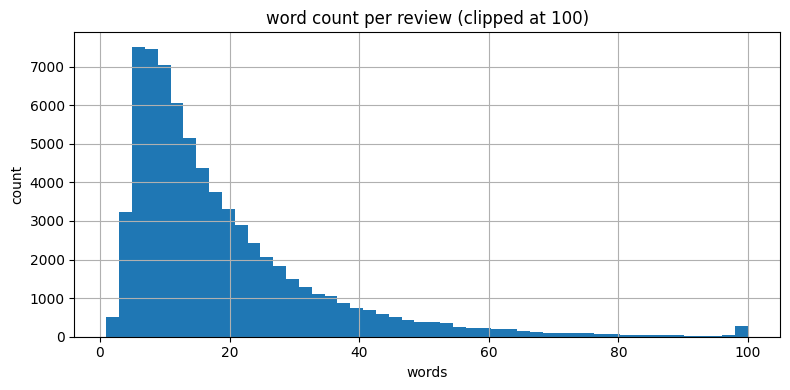

= SAD
                                                                                                     تو قیمتا زده بود پیتزا ۴ فصل و ۳۶۷۰۰ با ۲ تا نوشابه که میشه اونم ۵ میشه ۴۱۷۰۰ ولی از من ۴۸۷۰۰ گرفتن
                                                                                                                                                      اصلا" راضى نبودم ١ساعت و نیم طول کشید به دستم برسه
                            اصلا راضی نیستم با این که اولین بار نبود که به سیب سفارش میدادم اما اخرین بار خواهد بود. متاسفانه سفارشم با دو ساعت تاخیر به دستم رسید غذا هم کیفیت همیشگی را نداشت متاسفانه
                                                                                                               مرغ تریاکی اصلا مزه سس تریاکی نمیداد. ولی یه سس سفید رنگ داشت که مزه مایونز با روغن میداد
متاسفانه علارقم زحمت زیادی که برای پخت پیتزا کشیده شده بودند. همونطور که یک نفر دیگه هم در مورد پیتزا الفردو گفته بودند متاسفانه مرغ‌ها با حجم زیاد رو پیتزا ریخته شده ولی ظاهرا این مرغ فقط ا

In [4]:
TEXT_COL = "comment"
LABEL_COL = "label"

print("تعداد ردیف‌ها:", len(df))
print("\nمقادیر خالی:")
print(df[[TEXT_COL, LABEL_COL]].isna().sum())
print("\nتکراری‌ها بر اساس متن:", int(df.duplicated(subset=[TEXT_COL]).sum()))
print("\nتوزیع برچسب‌ها:")
print(df[LABEL_COL].value_counts(dropna=False))

df["n_words"] = df[TEXT_COL].astype(str).str.split().str.len()
print("\nآمار توصیفی طول نظرها (تعداد کلمه):")
print(df["n_words"].describe())

plt.figure(figsize=(8, 4))
df["n_words"].clip(upper=100).hist(bins=50)
plt.title("word count per review (clipped at 100)")
plt.xlabel("words")
plt.ylabel("count")
plt.tight_layout()
plt.savefig(f"{BASE_DIR}/reports/figures/word_count_dist.png", dpi=150)
plt.show()

pd.set_option("display.max_colwidth", 200)
for lab in df[LABEL_COL].dropna().unique():
    print("=", lab)
    print(df[df[LABEL_COL] == lab][TEXT_COL].sample(5, random_state=1).to_string(index=False))

In [5]:
raw_path = f"{BASE_DIR}/data/raw/snappfood_raw.parquet"
df.to_parquet(raw_path, index=False)
print("ذخیره شد، حجم:", os.path.getsize(raw_path) // 1024, "KB")

bad_mask = df["label"].astype(str).isin(["0", "1"])
good_mask = df["label"].isin(["HAPPY", "SAD"])

bad = df[bad_mask]
print("تعداد ردیف خراب:", len(bad))
print(bad["source_file"].value_counts())
display(bad.head(10))

good = df[(~bad_mask) & good_mask][["comment", "label"]].copy()
good["rescued"] = False

fixed = pd.DataFrame({
    "comment": bad["Unnamed: 0"],
    "label": bad["comment"],
})
fixed["rescued"] = True

df_all = pd.concat([good, fixed], ignore_index=True)
assert "rescued" in df_all.columns and len(df_all) == len(df)

print("کل ردیف‌ها پس از بازیابی:", len(df_all))
print(df_all["label"].value_counts())
print("بازیابی‌شده‌ها:", int(df_all["rescued"].sum()))

ذخیره شد، حجم: 5554 KB
تعداد ردیف خراب: 520
source_file
Snappfood - Sentiment Analysis.csv    520
Name: count, dtype: int64


,Unnamed: 0,comment,label,label_id,source_file,n_words
21,هزار پول ساندویچ شد، ولی بیشترش قارچ بود,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
89,ساعت و نیم تاخیر برای ارسال یک عدد ساندویچ! و تحویل ساندویخ سرد و خیس!,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
161,تومن پیتزا خریدم سس نداده بود بدون سس خوردم,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
180,تا شونه تخم مرغ را نیاوردید,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
243,- سریع رسید ۲- بسته بندی مناسب بود ۳- دور چین خوراک کباب لقمه ضعیف بود، برای سه پرس غذا فقط یک برش پیاز، یک بسته سبزی و دو عدد فلفل کوچیک و یه اسلایس کوچک ته دیگ … همین!!,HAPPY,0,NaN,Snappfood - Sentiment Analysis.csv,1
287,تا سنگگ یک ساعت و بیست دقیقه باید طول بکشه؟!!! غذا تموم شد نیم ساعت بعد سنگگ‌ رسید,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
288,عدد بستنی داخل سفارشم بود اما ارسال نشد حتی داخل فاکتور هم تیک نخورده اگر نداشتن باید اطلاع میدادن ممنون,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
415,ساعت ۳۰ دقیقه طول کشید تا آورد اصلا وقت مردم مهم نیست براتون,HAPPY,0,NaN,Snappfood - Sentiment Analysis.csv,1
480,ساعت طول کشید تا برسه.. ‌ جلو مهمونا آبروم رفت,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
507,تیکه فیله اندازه سه بند انگشت. واقعات جالب بود. مگه میشه آخه. من از همه رستورانهای محدوده خرید کردم. ولی امروز شاخ درآوردم. کیفیت خوب بود ولی واقعا حجم غذا خیلی کم بود,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1


کل ردیف‌ها پس از بازیابی: 70000
label
SAD      35000
HAPPY    35000
Name: count, dtype: int64
بازیابی‌شده‌ها: 520


In [6]:
normalizer = Normalizer()
digit_map = str.maketrans("۰۱۲۳۴۵۶۷۸۹٠١٢٣٤٥٦٧٨٩", "01234567890123456789")

def clean_text(t):
    t = str(t)
    t = t.replace("\u200f", "").replace("\ufeff", "")
    t = normalizer.normalize(t)
    t = t.translate(digit_map)
    t = re.sub(r"https?://\S+", " ", t)
    t = re.sub(r"([^\W\d_])\1{2,}", r"\1\1", t)
    t = re.sub(r"(\d)([^\W\d_])", r"\1 \2", t)
    t = re.sub(r"([^\W\d_])(\d)", r"\1 \2", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

d = df_all.copy()
d["is_negative"] = (d["label"] == "SAD").astype(int)
d["text"] = d["comment"].map(clean_text)
d = d[d["text"].str.len() > 0]

for i in d.sample(5, random_state=3).index:
    print("قبل :", d.loc[i, "comment"])
    print("بعد :", d.loc[i, "text"])
    print()

conf = d.groupby("text")["is_negative"].nunique()
conf = conf[conf > 1]
print("تکراری واقعی:", int(d.duplicated("text").sum()))
print("متن با برچسب متناقض:", len(conf))

d = d[~d["text"].isin(conf.index)]
d = d.drop_duplicates("text")
d["n_words"] = d["text"].str.split().str.len()
df_clean = d.reset_index(drop=True)

print("ردیف نهایی:", len(df_clean))
print(df_clean["is_negative"].value_counts(normalize=True).round(3))
print("بازیابی‌شده‌ها:", int(df_clean["rescued"].sum()))
print("نظر <= 2 کلمه:", int((df_clean["n_words"] <= 2).sum()))

clean_path = f"{BASE_DIR}/data/interim/snappfood_clean.parquet"
df_clean[["text", "is_negative", "n_words", "rescued"]].to_parquet(clean_path, index=False)
print("ذخیره شد:", clean_path)

قبل : سبزیجات عالی بود همه تازه بودن
بعد : سبزیجات عالی بود همه تازه بودن

قبل : کیک‌ تکون خورده بود و خراب شده بود …..
بعد : کیک تکون خورده بود و خراب‌شده بود …..

قبل : سفارش با کیفیت خوب همیشگی و در زمان قابل قبول تحویل داده شد.
بعد : سفارش با کیفیت خوب همیشگی و در زمان قابل‌قبول تحویل داده شد.

قبل : خسته نباشید …بموقع رسید ….
بعد : خسته نباشید …بموقع رسید ….

قبل : من ۱ کیلو دسر شکلاتی سفارش داده بودم، فقط ۴ عدد شیرینی با وزن حدود ۴۰۰ گرم، بدون هیچ شباهتی به سفارشم تحویل گردید و قبل از چک کردن جعبه، پیک هم سریع رفت. بسیار ناراضی … هم از ناتلی و هم از پیک
بعد : من 1 کیلو دسر شکلاتی سفارش داده بودم، فقط 4 عدد شیرینی با وزن حدود 400 گرم، بدون هیچ شباهتی به سفارشم تحویل گردید و قبل از چک کردن جعبه، پیک هم سریع رفت. بسیار ناراضی … هم از ناتلی و هم از پیک

تکراری واقعی: 55
متن با برچسب متناقض: 4
ردیف نهایی: 69941
is_negative
1    0.5
0    0.5
Name: proportion, dtype: float64
بازیابی‌شده‌ها: 520
نظر <= 2 کلمه: 2
ذخیره شد: /content/cx-radar/data/interim/snappfood_clean.parquet


In [7]:
strat = df_clean["is_negative"].astype(str) + "_" + df_clean["rescued"].astype(str)
train_val, test = train_test_split(
    df_clean, test_size=0.15, random_state=42, stratify=strat
)

strat_tv = train_val["is_negative"].astype(str) + "_" + train_val["rescued"].astype(str)
train, val = train_test_split(
    train_val, test_size=0.15 / 0.85, random_state=42, stratify=strat_tv
)

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(
        name,
        len(part),
        "| منفی:",
        round(part["is_negative"].mean(), 3),
        "| بازیابی‌شده:",
        int(part["rescued"].sum()),
    )

train.to_parquet(f"{BASE_DIR}/data/processed/train.parquet", index=False)
val.to_parquet(f"{BASE_DIR}/data/processed/val.parquet", index=False)
test.to_parquet(f"{BASE_DIR}/data/processed/test.parquet", index=False)

pipe = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=1000, C=1.0),
)
pipe.fit(train["text"], train["is_negative"])
pred = pipe.predict(val["text"])

print("Accuracy:", round(accuracy_score(val["is_negative"], pred), 4))
print("Macro-F1:", round(f1_score(val["is_negative"], pred, average="macro"), 4))
print(classification_report(val["is_negative"], pred, target_names=["مثبت", "منفی"], digits=3))
print(confusion_matrix(val["is_negative"], pred))

val_eval = val.copy()
val_eval["pred"] = pred
for flag, g in val_eval.groupby("rescued"):
    acc = (g["pred"] == g["is_negative"]).mean()
    print("rescued:", flag, "| تعداد n:", len(g), "| accuracy:", round(acc, 4))

proba = pipe.predict_proba(val["text"])[:, 1]
val_eval["p_neg"] = proba
wrong = val_eval[val_eval["pred"] != val_eval["is_negative"]].copy()
wrong["confidence"] = wrong["p_neg"].where(wrong["pred"] == 1, 1 - wrong["p_neg"])

pd.set_option("display.max_colwidth", 200)
print("تعداد خطا:", len(wrong))
display(wrong.sort_values("confidence", ascending=False)[["text", "is_negative", "confidence"]].head(15))

sample_wrong = wrong.sample(min(50, len(wrong)), random_state=11)
for i, (_, r) in enumerate(sample_wrong.iterrows(), 1):
    lab = "منفی" if r["is_negative"] == 1 else "مثبت"
    print(f"{i}. [برچسب: {lab}] {r['text']}\n")

tfidf = pipe.named_steps["tfidfvectorizer"]
lr = pipe.named_steps["logisticregression"]
names = np.array(tfidf.get_feature_names_out())
order = lr.coef_[0].argsort()

print("نشانه‌های مثبت:", list(names[order[:20]]))
print("\nنشانه‌های منفی:", list(names[order[-20:][::-1]]))

def run(name, vec, C):
    t0 = time.time()
    m = make_pipeline(vec, LogisticRegression(max_iter=2000, C=C))
    m.fit(train["text"], train["is_negative"])
    p = m.predict(val["text"])
    print(
        f"{name:20s} acc={accuracy_score(val['is_negative'], p):.4f} "
        f"macroF1={f1_score(val['is_negative'], p, average='macro'):.4f} "
        f"({time.time() - t0:.0f}s)"
    )

for C in [0.5, 1, 3, 10]:
    run(f"word(1,2) C={C}", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), C)
run("word(1,3) C=3", TfidfVectorizer(ngram_range=(1, 3), min_df=2, sublinear_tf=True), 3)
run("char(2,5) C=3", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True), 3)

train 48958 | منفی: 0.5 | بازیابی‌شده: 364
val 10491 | منفی: 0.5 | بازیابی‌شده: 78
test 10492 | منفی: 0.5 | بازیابی‌شده: 78
Accuracy: 0.8634
Macro-F1: 0.8631
              precision    recall  f1-score   support

        مثبت      0.902     0.815     0.856      5244
        منفی      0.832     0.911     0.870      5247

    accuracy                          0.863     10491
   macro avg      0.867     0.863     0.863     10491
weighted avg      0.867     0.863     0.863     10491

[[4276  968]
 [ 465 4782]]
rescued: False | تعداد n: 10413 | accuracy: 0.8634
rescued: True | تعداد n: 78 | accuracy: 0.859
تعداد خطا: 1433


,text,is_negative,confidence
27801,در کل خوب بود به موقع رسید و مرغاش خوش‌مزه بود مرسی,1,0.999109
23042,عالی هم زود رسید هم تازه بود ممنون,1,0.998916
65151,مثل همیشه تازه،، گرم و عالی.. با تشکر,1,0.997132
66629,واقعا غذای بسیار خوشمزه بود طعمش خیلی عالی بود,1,0.996986
55906,البته خیلی سریع سفارشمون رسید ممنون,1,0.993881
28343,عالی نبود. ولی خوب بود,1,0.991006
53465,بسیار خوش طمع و عالی,1,0.984929
40700,یعنی مثل همیشه تازه و خوشمزه و به موقع,1,0.984041
24958,شکلات پوست پرتقال خیلی معمولی بود نصف شکلاتا ریخته و فقط پوست پرتقالش مونده! شکری برشی واقعا خیلی بدمزه بود بوی بدی درست شبیه ماهی خام می‌داد! اصلا نتونستم بخورم و تازه هم نبود …,0,0.983089
61156,پیک عالی بود تشکر از آقای جباری پیک عالی شیرینی فروشی,1,0.983081


1. [برچسب: منفی] خوب بود بد نبود ولی کاش جوجه رو زعفرانی میکردین

2. [برچسب: مثبت] یه سر و گردن از رستوران‌های هم قیمت خودش بالاتره

3. [برچسب: مثبت] سیب زمینیش که نصف ظرف بود پیتزام بد نبود

4. [برچسب: مثبت] گوشت رست بیف خیلی سفته

5. [برچسب: مثبت] خیلی بی‌مزه بود، این غذا زیر ده تومن ارزش داشت نه 28 تومن

6. [برچسب: مثبت] حجم سس پنیر خیلی کم بود غذا دیر رسید سیب‌زمینی مونده بود

7. [برچسب: منفی] کیفیت غذا خوب بود ولی متاسفانه سرد بود

8. [برچسب: مثبت] پیک خیلی بد بود

9. [برچسب: مثبت] با این حال که من با غذای تند مشکلی ندارم ولی متاسفانه تندی بیش از حد بود ودیگه مزه پیتزا را احساس نمی‌کردی و اینکه پیتزا باید برشته باشه.

10. [برچسب: مثبت] کیک طمع شکلات کمی داشت و شیرینی آن زیاد بود.

11. [برچسب: مثبت] خورشت‌ها به شدت چرب اند و جوجه مخلفات خوبی ندارد

12. [برچسب: مثبت] ای کاش تشریف میاوردن طبقه 2 با اسانسور بنده رو پایین نمیکشوندن متاسفم برای پیک

13. [برچسب: مثبت] برخلاف همیشه کباب شور و سفت بود برنج هم طعم خوبی نداشت

14. [برچسب: مثبت] متاسفانه سوپ ارسال نشده بود

15. [برچسب: مثبت] 

GPU: Tesla T4


config.json:   0%|          | 0.00/440 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.20M [00:00<?, ?B/s]

تعداد بچ‌ها: 1530 164


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  654MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	thos

model.safetensors: reconstructing file:   0%|          |  0.00B /  654MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch 1 batch 0/1530 loss 0.8631
epoch 1 batch 300/1530 loss 0.4418
epoch 1 batch 600/1530 loss 0.3423
epoch 1 batch 900/1530 loss 0.2418
epoch 1 batch 1200/1530 loss 0.2651
epoch 1 batch 1500/1530 loss 0.5915
>>> epoch 1: val acc 0.8732 macroF1=0.8726
epoch 2 batch 0/1530 loss 0.2524
epoch 2 batch 300/1530 loss 0.4382
epoch 2 batch 600/1530 loss 0.1881
epoch 2 batch 900/1530 loss 0.2107
epoch 2 batch 1200/1530 loss 0.2392
epoch 2 batch 1500/1530 loss 0.1645
>>> epoch 2: val acc 0.8783 macroF1=0.8780
فقط TF-IDF درست: 281
فقط BERT درست: 437
هر دو غلط: 996
[[4375  869]
 [ 408 4839]]
              precision    recall  f1-score   support

        مثبت      0.915     0.834     0.873      5244
        منفی      0.848     0.922     0.883      5247

    accuracy                          0.878     10491
   macro avg      0.881     0.878     0.878     10491
weighted avg      0.881     0.878     0.878     10491

تعداد کل موارد هر دو غلط: 996

توزیع برچسب واقعی در موارد هر دو غلط:
برچسب_واقعی
مثبت

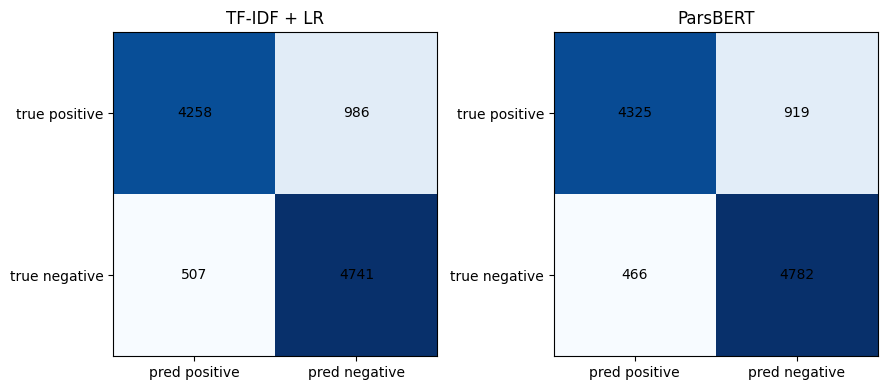

In [8]:
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

MODEL = "HooshvareLab/bert-fa-base-uncased"
tok = AutoTokenizer.from_pretrained(MODEL)

train = pd.read_parquet(f"{BASE_DIR}/data/processed/train.parquet")
val = pd.read_parquet(f"{BASE_DIR}/data/processed/val.parquet")

def encode(df_part):
    enc = tok(df_part["text"].tolist(), truncation=True, max_length=96)
    y = df_part["is_negative"].tolist()
    return [
        {
            "input_ids": enc["input_ids"][i],
            "attention_mask": enc["attention_mask"][i],
            "labels": int(y[i]),
        }
        for i in range(len(df_part))
    ]

collate = DataCollatorWithPadding(tok)
train_dl = DataLoader(encode(train), batch_size=32, shuffle=True, collate_fn=collate)
val_dl = DataLoader(encode(val), batch_size=64, shuffle=False, collate_fn=collate)
print("تعداد بچ‌ها:", len(train_dl), len(val_dl))

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2).to(device)

EPOCHS = 2
opt = torch.optim.AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
total = len(train_dl) * EPOCHS
sched = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

def predict(dl):
    model.eval()
    out = []
    with torch.no_grad():
        for b in dl:
            inputs = {k: v.to(device) for k, v in b.items() if k != "labels"}
            with torch.amp.autocast("cuda", dtype=torch.float16, enabled=(device == "cuda")):
                out.append(model(**inputs).logits.argmax(-1).cpu())
    return torch.cat(out).numpy()

for ep in range(EPOCHS):
    model.train()
    for i, b in enumerate(train_dl):
        b = {k: v.to(device) for k, v in b.items()}
        with torch.amp.autocast("cuda", dtype=torch.float16, enabled=(device == "cuda")):
            loss = model(**b).loss
        opt.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        sched.step()
        if i % 300 == 0:
            print(f"epoch {ep+1} batch {i}/{len(train_dl)} loss {loss.item():.4f}")

    p_val_bert = predict(val_dl)
    y_v = val["is_negative"].values
    print(
        f">>> epoch {ep+1}: val acc {accuracy_score(y_v, p_val_bert):.4f} "
        f"macroF1={f1_score(y_v, p_val_bert, average='macro'):.4f}"
    )

val_eval["pred_bert"] = p_val_bert
y = val_eval["is_negative"]
tf_ok = val_eval["pred"] == y
bt_ok = val_eval["pred_bert"] == y

print("فقط TF-IDF درست:", int((tf_ok & ~bt_ok).sum()))
print("فقط BERT درست:", int((~tf_ok & bt_ok).sum()))
print("هر دو غلط:", int((~tf_ok & ~bt_ok).sum()))
print(confusion_matrix(y, p_val_bert))
print(classification_report(y, p_val_bert, target_names=["مثبت", "منفی"], digits=3))

both_wrong = val_eval[
    (val_eval["pred"] != val_eval["is_negative"])
    & (val_eval["pred_bert"] != val_eval["is_negative"])
].copy()
print("تعداد کل موارد هر دو غلط:", len(both_wrong))

label_map = {0: "مثبت (0)", 1: "منفی (1)"}
pred_map = {0: "مثبت (0)", 1: "منفی (1)"}
both_wrong["برچسب_واقعی"] = both_wrong["is_negative"].map(label_map)
both_wrong["پیش‌بینی_هر_دو"] = both_wrong["pred_bert"].map(pred_map)

print("\nتوزیع برچسب واقعی در موارد هر دو غلط:")
print(both_wrong["برچسب_واقعی"].value_counts())

sample_n = min(25, len(both_wrong))
sample_df = both_wrong.sample(n=sample_n, random_state=42)
print(f"\n--- نمایش {sample_n} نمونه تصادفی ---")
for idx, row in sample_df.iterrows():
    clean_txt = " ".join(str(row["text"]).split())
    print(f"[{idx}] برچسب واقعی: {row['برچسب_واقعی']} | پیش‌بینی هر دو مدل: {row['پیش‌بینی_هر_دو']}")
    print(f"    متن: {clean_txt}\n")

test = pd.read_parquet(f"{BASE_DIR}/data/processed/test.parquet")
y_test = test["is_negative"].values
test_dl = DataLoader(encode(test), batch_size=64, shuffle=False, collate_fn=collate)

p_tfidf = pipe.predict(test["text"])
p_bert = predict(test_dl)

for name, p in [("TF-IDF", p_tfidf), ("ParsBERT", p_bert)]:
    acc = accuracy_score(y_test, p)
    f1 = f1_score(y_test, p, average="macro")
    ci = 1.96 * np.sqrt(acc * (1 - acc) / len(y_test))
    print(f"{name:9s} acc={acc:.4f} (±{ci:.4f}) macroF1={f1:.4f}")
    print(confusion_matrix(y_test, p))

only_bert = int(((p_tfidf != y_test) & (p_bert == y_test)).sum())
only_tfidf = int(((p_tfidf == y_test) & (p_bert != y_test)).sum())
both_wrong_test = int(((p_tfidf != y_test) & (p_bert != y_test)).sum())
print("فقط BERT درست:", only_bert, "| فقط TF-IDF درست:", only_tfidf, "| هر دو غلط:", both_wrong_test)
print("p-value:", binomtest(only_bert, only_bert + only_tfidf, 0.5).pvalue)

r = test["rescued"].values
print(
    "rescued acc TF-IDF:",
    round((p_tfidf[r] == y_test[r]).mean(), 3),
    "| BERT:",
    round((p_bert[r] == y_test[r]).mean(), 3),
)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, p) in zip(axes, [("TF-IDF + LR", p_tfidf), ("ParsBERT", p_bert)]):
    cm = confusion_matrix(y_test, p)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["pred positive", "pred negative"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["true positive", "true negative"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
fig_path = f"{BASE_DIR}/reports/figures/confusion_matrix.png"
plt.savefig(fig_path, dpi=150)
plt.show()

res = {
    "tfidf_lr": {
        "acc": float(accuracy_score(y_test, p_tfidf)),
        "macro_f1": float(f1_score(y_test, p_tfidf, average="macro")),
    },
    "parsbert": {
        "acc": float(accuracy_score(y_test, p_bert)),
        "macro_f1": float(f1_score(y_test, p_bert, average="macro")),
    },
    "n_test": int(len(test)),
}
json_path = f"{BASE_DIR}/reports/results.json"
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(res, f, indent=2, ensure_ascii=False)

تعداد نظر منفی: 34986
بدون هیچ موضوع (V1): 0.215
بدون هیچ موضوع (V2): 0.207


,v1_pct,v2_pct,diff_pp
food_quality,44.2,48.2,4.0
cold_food,15.0,15.1,0.1
small_portion,16.0,13.8,-2.2
delay,12.4,13.0,0.6
price,12.7,11.1,-1.6
damage_packaging,7.4,6.9,-0.5
missing_wrong_item,8.4,6.7,-1.7
courier,6.0,6.0,0.0
app_support,2.6,1.9,-0.7


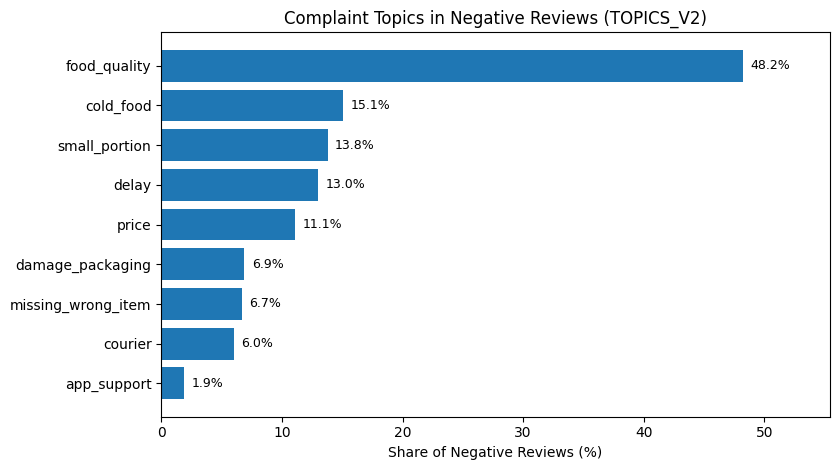


۲۵ نمونه بدون موضوع در V2:
                                                                                                                                                    همبرگراش بد نیست … ولی بقیه غذاهاش به سختی میشه خورد
                                                                                                            سلام سالاد من را نفرستادند اصلا تو فیش تحویل سالاد نخورده ولی تو سفارش اسنپ مبلغش دریافت شده
                                                                                                                                                                                      کباب فوق‌العاده بد
                                                                                                                                                  محتویات داخل نان رفته‌رفته کمتر می‌شود و این محسوس است
                                                                                                                                                                        

In [9]:
if "df_clean" not in globals():
    df_clean = pd.read_parquet(f"{BASE_DIR}/data/interim/snappfood_clean.parquet")

TOPICS_V1 = {
    "delay": r"\bساعت\b|دیرتر|طول کشید|معطل|منتظر|دقیقه|\bدیر\b|تاخیر|تأخیر",
    "cold_food": r"\bسرد\b|ولرم|گرم نبود|\bیخ\b|یخ کرده|یخ زده",
    "small_portion": r"\bکم\b|حجم|مقدار|ریز|کوچک|کوچیک|سیر نمی|نصف",
    "food_quality": (
        r"خام|نپخته|سوخته|بدمزه|بی مزه|شور|چرب|تازه نبود|فاسد|کیفیت|سفت|خشک|"
        r"\bبو\b|بوی|کهنه|مونده|مانده"
    ),
    "damage_packaging": r"شکسته|نشت|ترکیده|آب شده|به هم ریخته|خراب شده|پاره|بسته بندی|ریخته",
    "missing_wrong_item": (
        r"نفرستاد|نیاورد|ارسال نشده|ارسال نکرد|فراموش|اشتباه|به جای|بجای|ناقص|"
        r"جا افتاده|نگذاشت|نذاشت|موجود نبود"
    ),
    "price": r"هزار|تخفیف|\bپول\b|قیمت|گرون|گران|هزینه|تومن|تومان|ارزش",
    "courier": r"\bپیک\b|موتوری|راننده|بی ادب|برخورد|زنگ نزد",
    "app_support": r"اپلیکیشن|برنامه|پشتیبان|پیگیری|لغو|کنسل|بازگشت وجه|\bاپ\b",
}

TOPICS_V2 = {
    "delay": (
        r"\b(?:زمان|ساعت|دیر|دیرتر|تاخیر|تأخیر|معطل|منتظر|دقیقه|پیش‌بینی|پیش بینی)\b"
        r"|طول کشید"
    ),
    "cold_food": (
        r"\b(?:سرد|ولرم|یخ)\b|گرم نبود|از یخچال"
        r"|نوشیدنی.{0,15}گرم|یخ کرده|یخ زده"
    ),
    "small_portion": (
        r"\b(?:حجم|مقدار|ریز|کوچک|کوچیک|نصف|کم)\b"
        r"|سیر نمی|انگشت شمار|خالی بود|مغزی.{0,10}نداشت"
    ),
    "food_quality": (
        r"\b(?:خام|نپخته|سوخته|بدمزه|بد مزه|بی‌مزه|بی مزه|شور|چرب|بو|بوی|"
        r"کهنه|مونده|مانده|موندگی|فاسد|کیفیت|سفت|خشک|لهیده|پلاسیده|نارس|تلخ|"
        r"انقضا|افتضاح|بدترین)\b"
        r"|تازه نبود|تازگی|مزه.{0,12}نمی‌داد|مزه.{0,12}نمی داد|مزه.{0,15}می‌داد|مزه.{0,15}می داد"
        r"|پخت روز نبود|خیلی بد|واقعا بد|جالب نبود"
    ),
    "damage_packaging": (
        r"\b(?:شکسته|نشت|ترکیده|پاره|له|کثیف)\b"
        r"|آب شده|به هم ریخته|خراب شده|بسته بندی|بسته‌بندی|ریخته شده"
        r"|جابجا شده|تغییر شکل|قاطی شده"
    ),
    "missing_wrong_item": (
        r"\b(?:نفرستاد|نیاورد|فراموش|اشتباه|ناقص|نگذاشت|نذاشت)\b"
        r"|ارسال نشده|ارسال نکرد|به جای|بجای|جا افتاده|موجود نبود"
        r"|بدون.{0,15}فرستاد|یه دونه فرستاد|به اسم.{0,15}آمد"
    ),
    "price": r"\b(?:هزار|تخفیف|پول|قیمت|گرون|گران|هزینه|تومن|تومان|ارزش)\b",
    "courier": r"\b(?:پیک|موتوری|راننده)\b|بی ادب|بی‌ادب|برخورد|زنگ نزد",
    "app_support": r"\b(?:اپلیکیشن|برنامه|پشتیبان|پیگیری|لغو|کنسل|اپ)\b|بازگشت وجه",
}

def run_topics(texts_series, topics_dict):
    res = pd.DataFrame(index=texts_series.index)
    for k, pat in topics_dict.items():
        res[k] = texts_series.str.contains(re.compile(pat), regex=True)
    res["n_topics"] = res.sum(axis=1)
    return res

neg = df_clean[df_clean["is_negative"] == 1].copy()
texts = neg["text"].fillna("").astype(str)

res_v1 = run_topics(texts, TOPICS_V1)
res_v2 = run_topics(texts, TOPICS_V2)
topic_cols = list(TOPICS_V1.keys())

print("تعداد نظر منفی:", len(neg))
print("بدون هیچ موضوع (V1):", round((res_v1["n_topics"] == 0).mean(), 3))
print("بدون هیچ موضوع (V2):", round((res_v2["n_topics"] == 0).mean(), 3))

comp = pd.DataFrame({
    "v1_pct": (res_v1[topic_cols].mean() * 100).round(1),
    "v2_pct": (res_v2[topic_cols].mean() * 100).round(1),
})
comp["diff_pp"] = (comp["v2_pct"] - comp["v1_pct"]).round(1)
comp = comp.sort_values("v2_pct", ascending=False)
display(comp)
comp.to_csv(f"{BASE_DIR}/reports/topics_comparison_v1_v2.csv", encoding="utf-8-sig")

plot_df = comp.sort_values("v2_pct", ascending=True)
plt.figure(figsize=(8.5, 4.8))
bars = plt.barh(plot_df.index, plot_df["v2_pct"])
plt.xlabel("Share of Negative Reviews (%)")
plt.title("Complaint Topics in Negative Reviews (TOPICS_V2)")
plt.xlim(0, max(plot_df["v2_pct"].max() * 1.15, 10))
for bar, val in zip(bars, plot_df["v2_pct"]):
    plt.text(val + 0.6, bar.get_y() + bar.get_height() / 2, f"{val:.1f}%", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(f"{BASE_DIR}/reports/figures/negative_topics_share.png", dpi=150)
plt.show()

print("\n۲۵ نمونه بدون موضوع در V2:")
print(texts[res_v2["n_topics"] == 0].sample(min(25, (res_v2["n_topics"] == 0).sum()), random_state=5).to_string(index=False))

# اختیاری: دانلود خروجی‌ها از کولب
# from google.colab import files
# files.download(f"{BASE_DIR}/reports/figures/confusion_matrix.png")
# files.download(f"{BASE_DIR}/reports/figures/negative_topics_share.png")
# files.download(f"{BASE_DIR}/reports/results.json")
# files.download(f"{BASE_DIR}/reports/topics_comparison_v1_v2.csv")

تعداد نظر منفی: 34986
بدون هیچ موضوع (V1): 0.215
بدون هیچ موضوع (V2): 0.207


,v1_pct,v2_pct,diff_pp
food_quality,44.2,48.2,4.0
cold_food,15.0,15.1,0.1
small_portion,16.0,13.8,-2.2
delay,12.4,13.0,0.6
price,12.7,11.1,-1.6
damage_packaging,7.4,6.9,-0.5
missing_wrong_item,8.4,6.7,-1.7
courier,6.0,6.0,0.0
app_support,2.6,1.9,-0.7


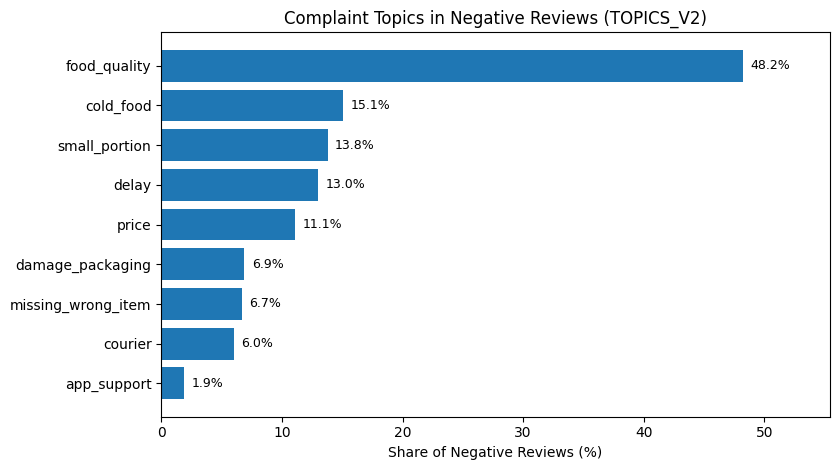


۲۵ نمونه بدون موضوع در V2:
                                                                                                                                                    همبرگراش بد نیست … ولی بقیه غذاهاش به سختی میشه خورد
                                                                                                            سلام سالاد من را نفرستادند اصلا تو فیش تحویل سالاد نخورده ولی تو سفارش اسنپ مبلغش دریافت شده
                                                                                                                                                                                      کباب فوق‌العاده بد
                                                                                                                                                  محتویات داخل نان رفته‌رفته کمتر می‌شود و این محسوس است
                                                                                                                                                                        

In [10]:
if "df_clean" not in globals():
    df_clean = pd.read_parquet(f"{BASE_DIR}/data/interim/snappfood_clean.parquet")

TOPICS_V1 = {
    "delay": r"\bساعت\b|دیرتر|طول کشید|معطل|منتظر|دقیقه|\bدیر\b|تاخیر|تأخیر",
    "cold_food": r"\bسرد\b|ولرم|گرم نبود|\bیخ\b|یخ کرده|یخ زده",
    "small_portion": r"\bکم\b|حجم|مقدار|ریز|کوچک|کوچیک|سیر نمی|نصف",
    "food_quality": (
        r"خام|نپخته|سوخته|بدمزه|بی مزه|شور|چرب|تازه نبود|فاسد|کیفیت|سفت|خشک|"
        r"\bبو\b|بوی|کهنه|مونده|مانده"
    ),
    "damage_packaging": r"شکسته|نشت|ترکیده|آب شده|به هم ریخته|خراب شده|پاره|بسته بندی|ریخته",
    "missing_wrong_item": (
        r"نفرستاد|نیاورد|ارسال نشده|ارسال نکرد|فراموش|اشتباه|به جای|بجای|ناقص|"
        r"جا افتاده|نگذاشت|نذاشت|موجود نبود"
    ),
    "price": r"هزار|تخفیف|\bپول\b|قیمت|گرون|گران|هزینه|تومن|تومان|ارزش",
    "courier": r"\bپیک\b|موتوری|راننده|بی ادب|برخورد|زنگ نزد",
    "app_support": r"اپلیکیشن|برنامه|پشتیبان|پیگیری|لغو|کنسل|بازگشت وجه|\bاپ\b",
}

TOPICS_V2 = {
    "delay": (
        r"\b(?:زمان|ساعت|دیر|دیرتر|تاخیر|تأخیر|معطل|منتظر|دقیقه|پیش‌بینی|پیش بینی)\b"
        r"|طول کشید"
    ),
    "cold_food": (
        r"\b(?:سرد|ولرم|یخ)\b|گرم نبود|از یخچال"
        r"|نوشیدنی.{0,15}گرم|یخ کرده|یخ زده"
    ),
    "small_portion": (
        r"\b(?:حجم|مقدار|ریز|کوچک|کوچیک|نصف|کم)\b"
        r"|سیر نمی|انگشت شمار|خالی بود|مغزی.{0,10}نداشت"
    ),
    "food_quality": (
        r"\b(?:خام|نپخته|سوخته|بدمزه|بد مزه|بی‌مزه|بی مزه|شور|چرب|بو|بوی|"
        r"کهنه|مونده|مانده|موندگی|فاسد|کیفیت|سفت|خشک|لهیده|پلاسیده|نارس|تلخ|"
        r"انقضا|افتضاح|بدترین)\b"
        r"|تازه نبود|تازگی|مزه.{0,12}نمی‌داد|مزه.{0,12}نمی داد|مزه.{0,15}می‌داد|مزه.{0,15}می داد"
        r"|پخت روز نبود|خیلی بد|واقعا بد|جالب نبود"
    ),
    "damage_packaging": (
        r"\b(?:شکسته|نشت|ترکیده|پاره|له|کثیف)\b"
        r"|آب شده|به هم ریخته|خراب شده|بسته بندی|بسته‌بندی|ریخته شده"
        r"|جابجا شده|تغییر شکل|قاطی شده"
    ),
    "missing_wrong_item": (
        r"\b(?:نفرستاد|نیاورد|فراموش|اشتباه|ناقص|نگذاشت|نذاشت)\b"
        r"|ارسال نشده|ارسال نکرد|به جای|بجای|جا افتاده|موجود نبود"
        r"|بدون.{0,15}فرستاد|یه دونه فرستاد|به اسم.{0,15}آمد"
    ),
    "price": r"\b(?:هزار|تخفیف|پول|قیمت|گرون|گران|هزینه|تومن|تومان|ارزش)\b",
    "courier": r"\b(?:پیک|موتوری|راننده)\b|بی ادب|بی‌ادب|برخورد|زنگ نزد",
    "app_support": r"\b(?:اپلیکیشن|برنامه|پشتیبان|پیگیری|لغو|کنسل|اپ)\b|بازگشت وجه",
}

def run_topics(texts_series, topics_dict):
    res = pd.DataFrame(index=texts_series.index)
    for k, pat in topics_dict.items():
        res[k] = texts_series.str.contains(re.compile(pat), regex=True)
    res["n_topics"] = res.sum(axis=1)
    return res

neg = df_clean[df_clean["is_negative"] == 1].copy()
texts = neg["text"].fillna("").astype(str)

res_v1 = run_topics(texts, TOPICS_V1)
res_v2 = run_topics(texts, TOPICS_V2)
topic_cols = list(TOPICS_V1.keys())

print("تعداد نظر منفی:", len(neg))
print("بدون هیچ موضوع (V1):", round((res_v1["n_topics"] == 0).mean(), 3))
print("بدون هیچ موضوع (V2):", round((res_v2["n_topics"] == 0).mean(), 3))

comp = pd.DataFrame({
    "v1_pct": (res_v1[topic_cols].mean() * 100).round(1),
    "v2_pct": (res_v2[topic_cols].mean() * 100).round(1),
})
comp["diff_pp"] = (comp["v2_pct"] - comp["v1_pct"]).round(1)
comp = comp.sort_values("v2_pct", ascending=False)
display(comp)
comp.to_csv(f"{BASE_DIR}/reports/topics_comparison_v1_v2.csv", encoding="utf-8-sig")

plot_df = comp.sort_values("v2_pct", ascending=True)
plt.figure(figsize=(8.5, 4.8))
bars = plt.barh(plot_df.index, plot_df["v2_pct"])
plt.xlabel("Share of Negative Reviews (%)")
plt.title("Complaint Topics in Negative Reviews (TOPICS_V2)")
plt.xlim(0, max(plot_df["v2_pct"].max() * 1.15, 10))
for bar, val in zip(bars, plot_df["v2_pct"]):
    plt.text(val + 0.6, bar.get_y() + bar.get_height() / 2, f"{val:.1f}%", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(f"{BASE_DIR}/reports/figures/negative_topics_share.png", dpi=150)
plt.show()

print("\n۲۵ نمونه بدون موضوع در V2:")
print(texts[res_v2["n_topics"] == 0].sample(min(25, (res_v2["n_topics"] == 0).sum()), random_state=5).to_string(index=False))

# اختیاری: دانلود خروجی‌ها از کولب
# from google.colab import files
# files.download(f"{BASE_DIR}/reports/figures/confusion_matrix.png")
# files.download(f"{BASE_DIR}/reports/figures/negative_topics_share.png")
# files.download(f"{BASE_DIR}/reports/results.json")
# files.download(f"{BASE_DIR}/reports/topics_comparison_v1_v2.csv")